In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [53]:
df = pd.read_csv('exoplanet_data.csv', comment = '#')
print(df.shape) #599 rows and 92 columns
print(df.columns.tolist())
''' IDk what pl_rade, default_flag, pl_controv_flag, ttv_flag, or rastr mean '''

(599, 92)
['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'soltype', 'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_masslim', 'st_met', 'st_meterr1', 'st_meterr2', 'st_metlim', 'st_metratio', 'st_

' IDk what pl_rade, default_flag, pl_controv_flag, ttv_flag, or rastr mean '

In [64]:
'''
Planet Name: pl_name, name most commonly used in literature. Seems fairly straightforawrd.
Host Name: hostname, stellar name most commonly used in literature. Again straightforward.
Discovery Method: discoverymethod, method by which the planet was first identified. Straightforward.
Spectral Type: st_spectype, classification of the star based on their spectral characteristics following the Morgan-Keenan system. Classifcation based on surface temp and intrinsic brightness.
Equilibrium Temperature [K]: pl_eqt, The equilibrium temperature of the planet as modeled by a black body heated only by its host star, or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body. Fair enough.
Planet Mass or Mass*sin(i) [Jupiter Mass]: pl_bmassj, Best planet mass estimate available, in order of preference: Mass, M*sin(i)/sin(i), or M*sin(i), depending on availability, and measured in Jupiter masses. Ok.
'''

df1 = df.loc[:,['pl_name','hostname','discoverymethod','st_spectype','pl_eqt','pl_bmassj']]
df2 = df1.dropna(axis=1)
print(df2.shape) #599 rows and 92 columns
print(df2.head())
print(df2.tail())
print(df2.columns.tolist())

(599, 3)
    pl_name hostname  discoverymethod
0   7 CMa c    7 CMa  Radial Velocity
1   7 CMa c    7 CMa  Radial Velocity
2  DMPP-1 b   DMPP-1  Radial Velocity
3  DMPP-1 b   DMPP-1  Radial Velocity
4  DMPP-1 c   DMPP-1  Radial Velocity
         pl_name   hostname  discoverymethod
594    bet Pic c    bet Pic  Radial Velocity
595  eps Ind A b  eps Ind A  Radial Velocity
596  eps Ind A b  eps Ind A  Radial Velocity
597  eps Ind A b  eps Ind A  Radial Velocity
598  eps Ind A b  eps Ind A  Radial Velocity
['pl_name', 'hostname', 'discoverymethod']


In [51]:
df["discoverymethod"].value_counts() # There are 7 discovery methods with the most common being transit and the least being disk kinematics
'''
Transit: the planet moves between earth and its host star, decreasing brightness.
Radial Velocity: the planets gravitational pull causes movement in its host star.
Microlensing: The host star system causes a change in brightness when infront of a background star and the planet increases this effect.
Imaging: the planet is directly imaged.
Transit Timing Variations: the exact transit time of a planet can reveal other planets in the system.
Eclipse Timing Variations: the planet is in a binary star system and changes the eclipse timing when one star eclipses another.
Disk Kinematics: the planet causes distrubances in gas within a disk surrounding a young star.
'''

'\nTransit: the planet moves between earth and its host star, decreasing brightness.\nRadial Velocity: the planets gravitational pull causes movement in its host star.\nMicrolensing: The host star system causes a change in brightness when infront of a background star and the planet increases this effect.\nImaging: the planet is directly imaged.\nTransit Timing Variations: the exact transit time of a planet can reveal other planets in the system.\nEclipse Timing Variations: the planet is in a binary star system and changes the eclipse timing when one star eclipses another.\nDisk Kinematics: the planet causes distrubances in gas within a disk surrounding a young star.\n'

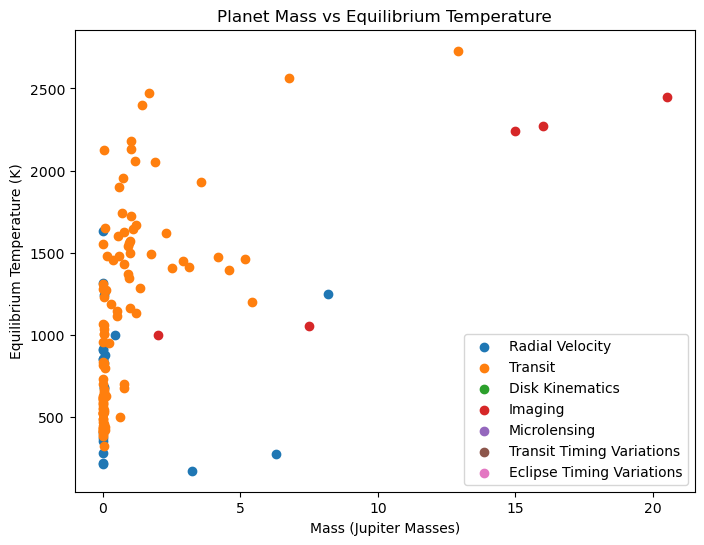

In [55]:
plt.figure(figsize=(8, 6))

for method in df["discoverymethod"].unique():
    booly = df[df["discoverymethod"] == method]
    plt.scatter(booly["pl_bmassj"], booly["pl_eqt"],label=method)
    
plt.xlabel("Mass (Jupiter Masses)")
plt.ylabel("Equilibrium Temperature (K)")
plt.title("Planet Mass vs Equilibrium Temperature")
plt.legend()
plt.show()

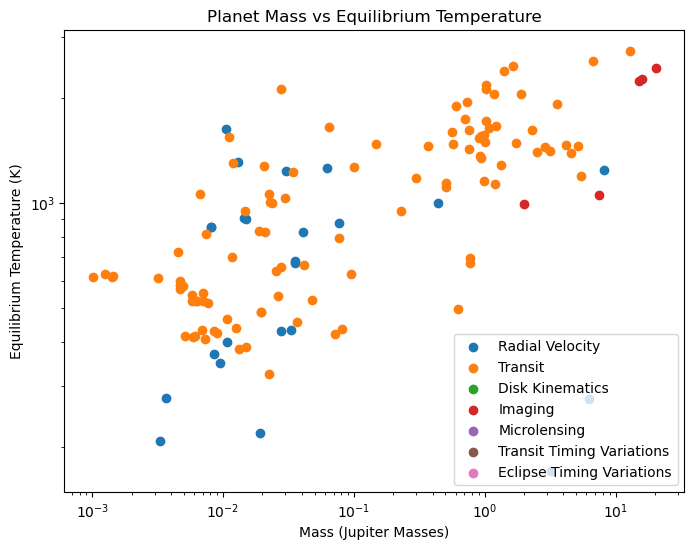

In [60]:
plt.figure(figsize=(8, 6))

for method in df["discoverymethod"].unique():
    booly = df[df["discoverymethod"] == method]
    plt.scatter(booly["pl_bmassj"], booly["pl_eqt"],label=method)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Mass (Jupiter Masses)")
plt.ylabel("Equilibrium Temperature (K)")
plt.title("Planet Mass vs Equilibrium Temperature")
plt.legend(loc = "lower right")
plt.show()

''' Exoplanets found by imaging are more likely to be massive'''

In [71]:
massives = df1[df1['pl_bmassj'] > 5]
coldest = massives.loc[massives['pl_eqt'].idxmin()]
print(coldest) # No the sun is spectral type G though they share luminosity class V

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object


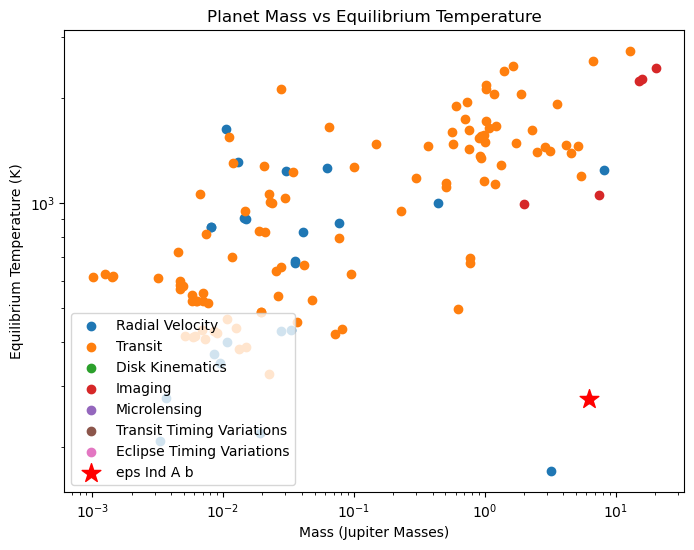

In [73]:
plt.figure(figsize=(8, 6))

for method in df["discoverymethod"].unique():
    booly = df[df["discoverymethod"] == method]
    plt.scatter(booly["pl_bmassj"], booly["pl_eqt"],label=method)

plt.scatter(coldest["pl_bmassj"],coldest["pl_eqt"],color="red",marker="*",s=200,label=coldest["pl_name"])

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Mass (Jupiter Masses)")
plt.ylabel("Equilibrium Temperature (K)")
plt.title("Planet Mass vs Equilibrium Temperature")
plt.legend(loc = "lower left")
plt.show()


In [75]:
''' In regards to the Nature paper:
Title: A temperate super-Jupiter imaged with JWST in the mid-infrared
Abstract Summary: In the star system of Eps Ind A, a radial velocity trend and astrometric acceleration hinted at the existance of a large exoplanet
in the system. Direct imaging found the planet though it was somewhat different than what was expected. Still it was very large and bright but not that warm.

The star in the paper matches the one in the data as they call it b in the Eps Ind A system. The temperature matches the paper and the mass is not directly stated in the abstract,
however they do say it is jupiter sized when in reality it is larger. It likely has an interesting carbon and oxygen ratio due to opacity in its atomosphere.
'''


' In regards o the Nature paper:\nTitle: A temperate super-Jupiter imaged with JWST in the mid-infrared\nAbstract Summary: In the star system of Eps Ind A, a radial velocity trend and astrometric acceleration hinted at the existance of a large exoplanet\nin the system. Direct imaging found the planet though it was somewhat different than what was expected. Still it was very large and bright but not that warm.\n\nThe star in the paper matches the one in the data as they call it b in the Eps Ind A system. The temperature matches the paper and the mass is not directly stated in the abstract,\nhowever they do say it is jupiter sized when in reality it is larger. It likely has an interesting carbon and oxygen ratio due to opacity in its atomosphere.\n'